# Naive Bayes Classification in Python

Dataset from Kaggle : **"Netflix Movies and TV Shows"** by *Shivam Bansal*  
Source: https://www.kaggle.com/datasets/shivamb/netflix-shows (requires login)

This version is set up to **prevent data leakage** with a 60 / 20 / 20 Train / Validation / Test split -- information from the Validation and Test Sets never reaches the exploration, and the Test Set never reaches the model or any choice we make.

---

### Essential Libraries

Let us begin by importing the essential Python Libraries.

> NumPy : Library for Numeric Computations in Python  
> Pandas : Library for Data Acquisition and Preparation  
> Matplotlib : Low-level library for Data Visualization  
> Seaborn : Higher-level library for Data Visualization  

In [1]:
import numpy as np
import pandas as pd
import seaborn as sb
import matplotlib.pyplot as plt 
sb.set() 

In [2]:
print("numpy version = "+np.__version__)
print("pandas version = "+pd.__version__)
print("seaborn version = "+sb.__version__)

numpy version = 2.5.4
pandas version = 3.0.6
seaborn version = 0.13.2


---

### Import the Dataset

The dataset is in CSV format; hence we use the `read_csv` function from Pandas.  
Immediately after importing, take a quick look at the data using the `head` function.

In [3]:
netflixdata = pd.read_csv('netflix_titles.csv')
netflixdata.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


Description of the dataset, as available on Kaggle, is as follows.

> **show_id** : Unique ID for each title  
> **type** : Whether the title is a Movie or a TV Show  
> **title** : Name of the title  
> **director** : Director(s) of the title  
> **cast** : Main actors in the title  
> **country** : Country or countries where the title was produced  
> **date_added** : Date the title was added to Netflix  
> **release_year** : Year the title was originally released  
> **rating** : Age rating of the title (e.g. TV-MA, PG-13)  
> **duration** : Minutes for movies, number of seasons for TV shows  
> **listed_in** : Genres of the title, separated by commas  
> **description** : Short summary of the title  

---

Check the vital statistics of the dataset using the `type` and `shape` attributes.

In [4]:
print("Data type : ", type(netflixdata))
print("Data dims : ", netflixdata.shape)

Data type :  <class 'pandas.DataFrame'>
Data dims :  (8807, 12)


Check the variables (and their types) in the dataset using the `dtypes` attribute.

In [5]:
print(netflixdata.dtypes)

show_id           str
type              str
title             str
director          str
cast              str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
description       str
dtype: object


---

## Clean the Dataset

Check the dataset for missing values, duplicates and invalid entries.  

**Leakage rule :** cleaning here only looks at **one row at a time** (is this rating valid? is this description missing?) or removes **repeated rows**. Nothing is calculated from the dataset as a whole, so cleaning before the split does not leak anything.

In [6]:
netflixdata.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


In [7]:
print(netflixdata.isnull().sum())

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


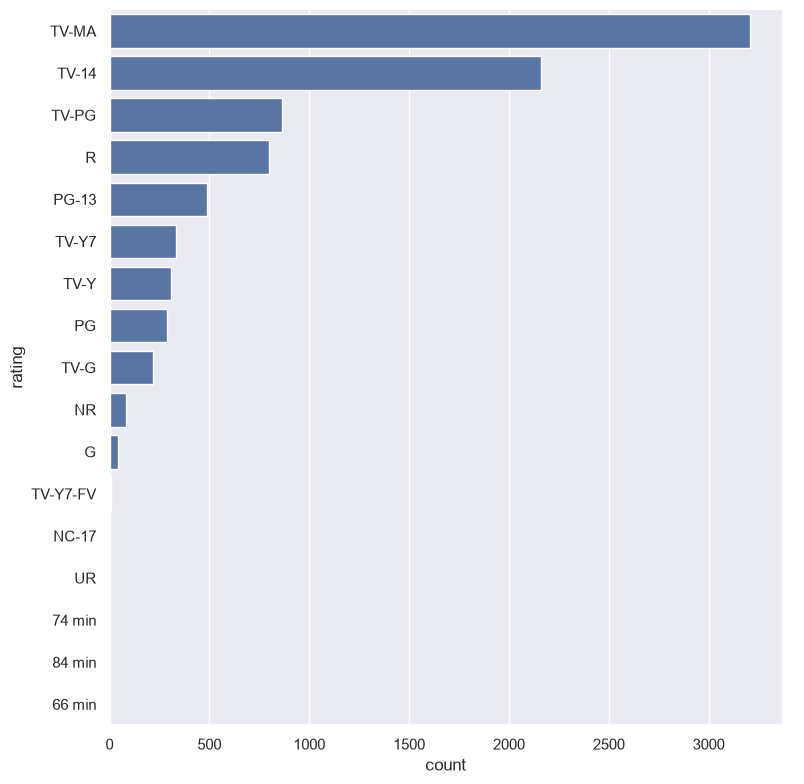

In [10]:
print(netflixdata["rating"].value_counts(dropna = False))

sb.catplot(y = "rating", data = netflixdata, kind = "count",
           order = netflixdata["rating"].value_counts().index, height = 8)

#### Movies and TV Shows in the Dataset

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


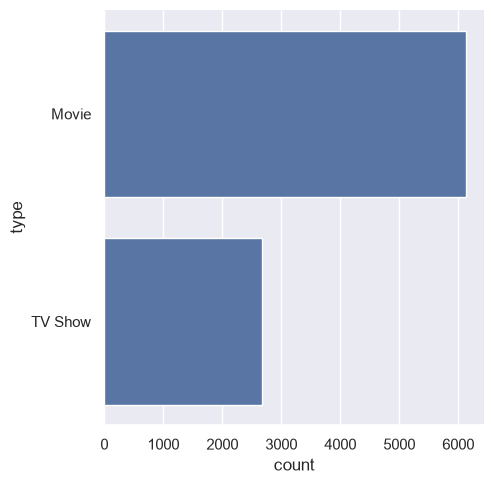

In [11]:
# Types in the Dataset
print(netflixdata["type"].value_counts())
sb.catplot(y = "type", data = netflixdata, kind = "count")

#### Remove Unusable Titles

Keep only titles with a valid age rating, a description and a genre.

In [12]:
# Valid Age Ratings
valid_ratings = ["TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G", "PG", "TV-PG",
                 "PG-13", "TV-14", "R", "TV-MA", "NC-17"]

# Keep only titles with a valid rating, a description and a genre
netflixclean = netflixdata[netflixdata["rating"].isin(valid_ratings)]
netflixclean = netflixclean.dropna(subset = ["description", "listed_in"])

# Check the sample sizes
print("Before Cleaning :", netflixdata.shape)
print("After Cleaning  :", netflixclean.shape)

Before Cleaning : (8807, 12)
After Cleaning  : (8717, 12)


#### Remove Duplicate and Near-Duplicate Descriptions

**Why this prevents leakage :** if the same (or almost the same) description is in both the Train Set and the Test Set, the model is tested on text it has already seen, and the Test accuracy looks better than it really is.  

Exact copies are easy to find. Near-copies are the same title in another language or version (e.g. *Game Over (Hindi Version)* and *Game Over (Telugu Version)*), where only a word or two differs.  
We catch them by comparing the **first 12 words** of each description, in lower case with punctuation removed.

In [14]:
# Remove exact duplicate descriptions
before = len(netflixclean)
netflixclean = netflixclean.drop_duplicates(subset = "description")
print("Exact duplicates removed :", before - len(netflixclean))

# Build a simple key : first 12 words, lower case, letters only
desc_key = netflixclean["description"].str.lower()
desc_key = desc_key.str.replace(r"[^a-z ]", "", regex = True)
desc_key = desc_key.str.split().str[:12].str.join(" ")

# Show a few near-duplicate pairs before removing them
near_dups = netflixclean[desc_key.duplicated(keep = False)]
print("Titles in near-duplicate groups :", len(near_dups))
near_dups.assign(key = desc_key).sort_values("key")[["title", "rating", "description"]].head(6)

Exact duplicates removed : 0
Titles in near-duplicate groups : 18


,title,rating,description
53,InuYasha the Movie 4: Fire on the Mystic Island,TV-PG,"Ai, a young half-demon who has escaped from Ho..."
7088,Inuyasha the Movie - L'isola del fuoco scarlatto,TV-PG,"Ai, a young half-demon who has escaped from Ho..."
3568,Game Over (Hindi Version),TV-MA,"As a series of murders hit close to home, a vi..."
3570,Game Over (Telugu Version),TV-MA,"As a series of murders hit close to home, a vi..."
1130,Seven Souls in the Skull Castle: Season Bird,TV-14,"Japan, 1590. Wandering samurai band together t..."
1131,Seven Souls in the Skull Castle: Season Flower,TV-14,"Japan, 1590. Wandering samurai band together t..."


In [15]:
# Keep only the first title of each near-duplicate group
before = len(netflixclean)
netflixclean = netflixclean[desc_key.duplicated() == False]
print("Near-duplicates removed :", before - len(netflixclean))
print("Final Dataset :", netflixclean.shape)

Near-duplicates removed : 12
Final Dataset : (8674, 12)


---

## Set up the Classification Problem

Response Variable : **Adult** (whether the title is rated 18+)     
Predictor Features : **description** and **listed_in** (genre)    

A title is **18+** if its rating is *R*, *TV-MA* or *NC-17*, and **Not 18+** otherwise.

In [16]:
# Create the Response Variable (row by row : uses only that title's own rating)
netflixclean["adult"] = netflixclean["rating"].isin(["R", "TV-MA", "NC-17"])
netflixclean["adult"] = netflixclean["adult"].map({True : "18+", False : "Not 18+"})

#### Combine Description and Genre

Each genre becomes a single token with a `g_` prefix -- e.g. *International Movies* becomes `g_International_Movies`.  
This is also row by row (a fixed text rule, nothing learnt from the data), so it does not leak.

In [17]:
# Convert the Genres of each title into Genre tokens
def genre_tokens(genres):
    tokens = []
    for g in genres.split(", "):
        g = g.replace(" ", "_").replace("'", "").replace("-", "_").replace("&", "and")
        tokens.append("g_" + g)
    return " ".join(tokens)

netflixclean["genre"] = netflixclean["listed_in"].apply(genre_tokens)

# Combine Description and Genre into a single text
netflixclean["text"] = netflixclean["description"] + " " + netflixclean["genre"]

# Check the first title
print(netflixclean["listed_in"].iloc[0])
print(netflixclean["text"].iloc[0])

Documentaries
As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable. g_Documentaries


---

## Split into Train, Validation and Test (60 / 20 / 20) -- FIRST

**Why this prevents leakage :** we split **before** any exploration or modelling, into three sets with three separate jobs.  

> **Train (60%)** : explore the data and fit the model  
> **Validation (20%)** : compare settings (`alpha`, which Predictors) and pick the best  
> **Test (20%)** : locked away, used **once** at the very end for the final score  

`train_test_split` only makes two sets, so we split twice : first lock away the Test Set (20%), then split the remaining 80% into Train and Validation.  
`stratify` keeps the same proportion of 18+ and Not 18+ titles in every set; `random_state` makes the split repeatable.

In [18]:
# Import train_test_split from sklearn
from sklearn.model_selection import train_test_split

# First split : lock away the Test Set (20% of all titles)
netflix_rest, netflix_test = train_test_split(netflixclean, test_size = 0.2,
                                              stratify = netflixclean["adult"], random_state = 42)

# Second split : the remaining 80% into Train (60% of all) and Validation (20% of all)
# 0.25 of the remaining 80% = 20% of the full dataset
netflix_train, netflix_val = train_test_split(netflix_rest, test_size = 0.25,
                                              stratify = netflix_rest["adult"], random_state = 42)

# Check the sample sizes
print("Train Set      :", netflix_train.shape)
print("Validation Set :", netflix_val.shape)
print("Test Set       :", netflix_test.shape)

Train Set      : (5204, 15)
Validation Set : (1735, 15)
Test Set       : (1735, 15)


In [19]:
# Check that every set keeps the same class proportions
print("Train      :", netflix_train["adult"].value_counts(normalize = True).round(3).to_dict())
print("Validation :", netflix_val["adult"].value_counts(normalize = True).round(3).to_dict())
print("Test       :", netflix_test["adult"].value_counts(normalize = True).round(3).to_dict())

Train      : {'Not 18+': 0.539, '18+': 0.461}
Validation : {'Not 18+': 0.539, '18+': 0.461}
Test       : {'Not 18+': 0.539, '18+': 0.461}


---

## Explore the Dataset -- Train Set only

**Why this prevents leakage :** every number and plot below is calculated on `netflix_train`.  
If we explored the whole dataset, patterns from the Validation or Test titles (e.g. which genres are mostly 18+) could steer our choices, and those sets would no longer be truly unseen.

#### Classes in the Train Set and the Baseline

adult
Not 18+    2803
18+        2401
Name: count, dtype: int64


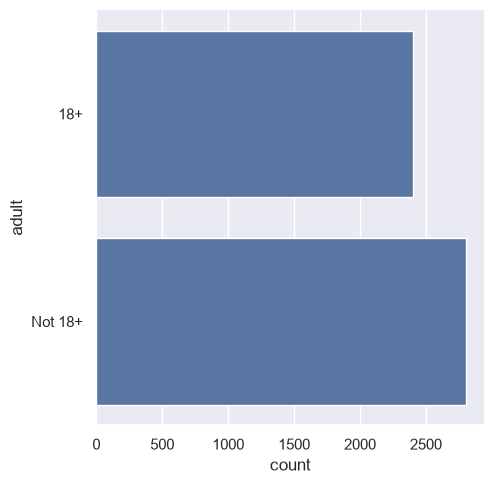

In [20]:
# Titles in each Class (Train Set)
print(netflix_train["adult"].value_counts())
sb.catplot(y = "adult", data = netflix_train, kind = "count")

In [24]:
# Baseline : always guess the most common class in the Train Set
majority_class = netflix_train["adult"].value_counts().idxmax()
print("Majority class \t\t:", majority_class)
print("Baseline Accuracy \t:", netflix_train["adult"].value_counts(normalize = True).max())

Majority class 		: Not 18+
Baseline Accuracy 	: 0.5386241352805534


#### Length of the Description

In [25]:
# Number of words in each Description (Train Set)
desc_len = pd.DataFrame(netflix_train["description"].str.split().str.len())
desc_len.columns = ["Length"]

# Summary Statistics for Description Length
desc_len.describe()

,Length
count,5204.000000
mean,23.880284
std,2.842202
min,10.000000
25%,22.000000
50%,24.000000
75%,26.000000
max,48.000000


<Axes: >

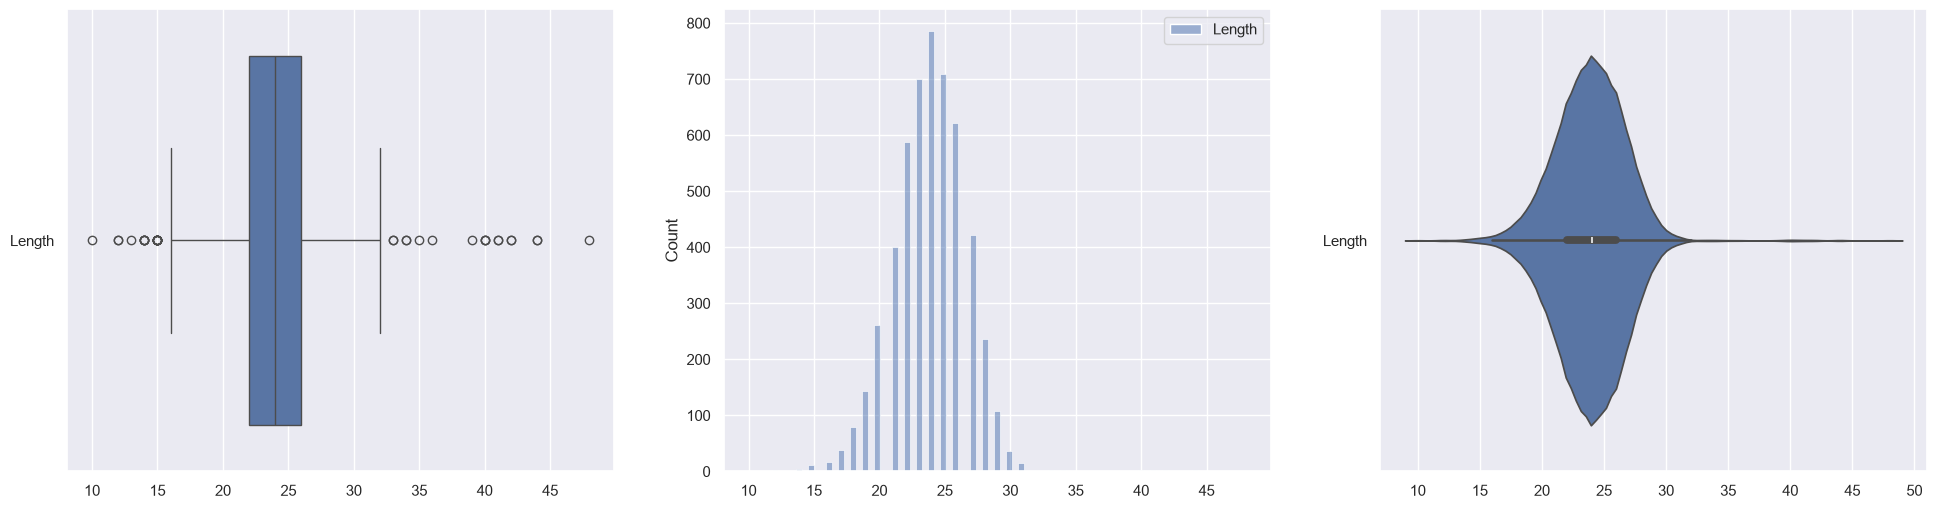

In [28]:
# Plot the distributions of Description Length
f, axes = plt.subplots(1, 3, figsize=(24, 6))
sb.boxplot(data = desc_len, orient = "h", ax = axes[0])
sb.histplot(data = desc_len, ax = axes[1])
sb.violinplot(data = desc_len, orient = "h", ax = axes[2])

<Axes: xlabel='Length', ylabel='adult'>

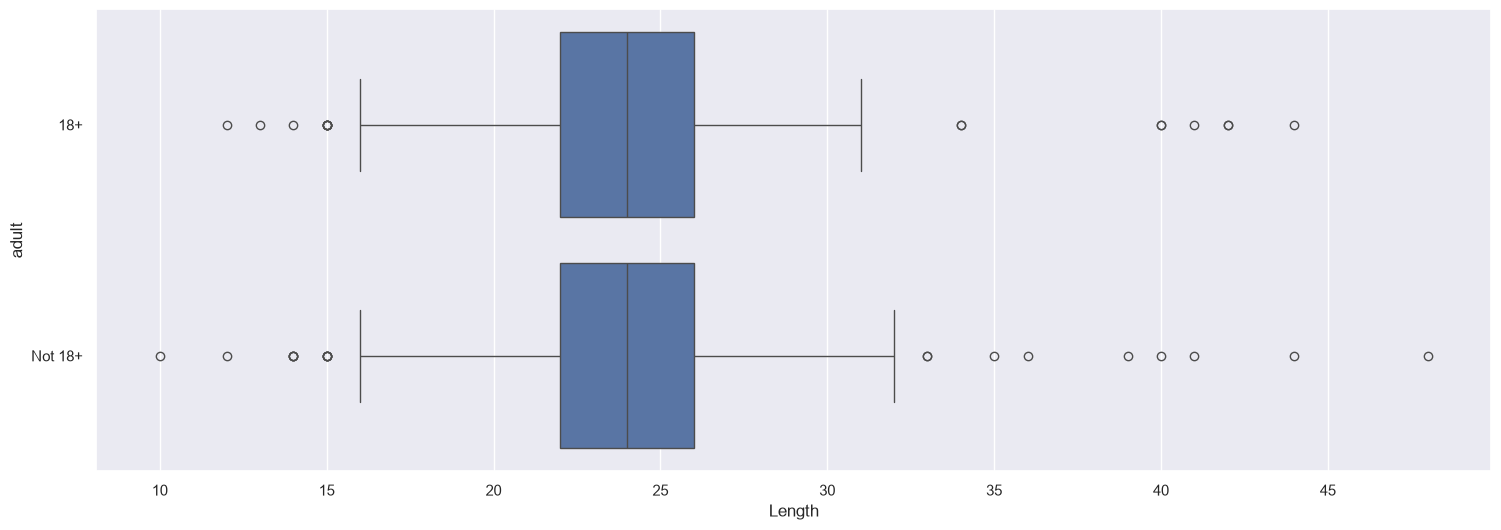

In [29]:
# Create a joint dataframe by concatenating Length and Adult
lenDF = pd.concat([desc_len, netflix_train["adult"]], axis = 1).reindex(desc_len.index)

# Joint Boxplot of Length against Adult
f = plt.figure(figsize=(18, 6))
sb.boxplot(x = "Length", y = "adult", data = lenDF, orient = "h")

#### Most Common Words in each Class

Text(0.5, 1.0, 'Share of descriptions containing each word (Train Set)')

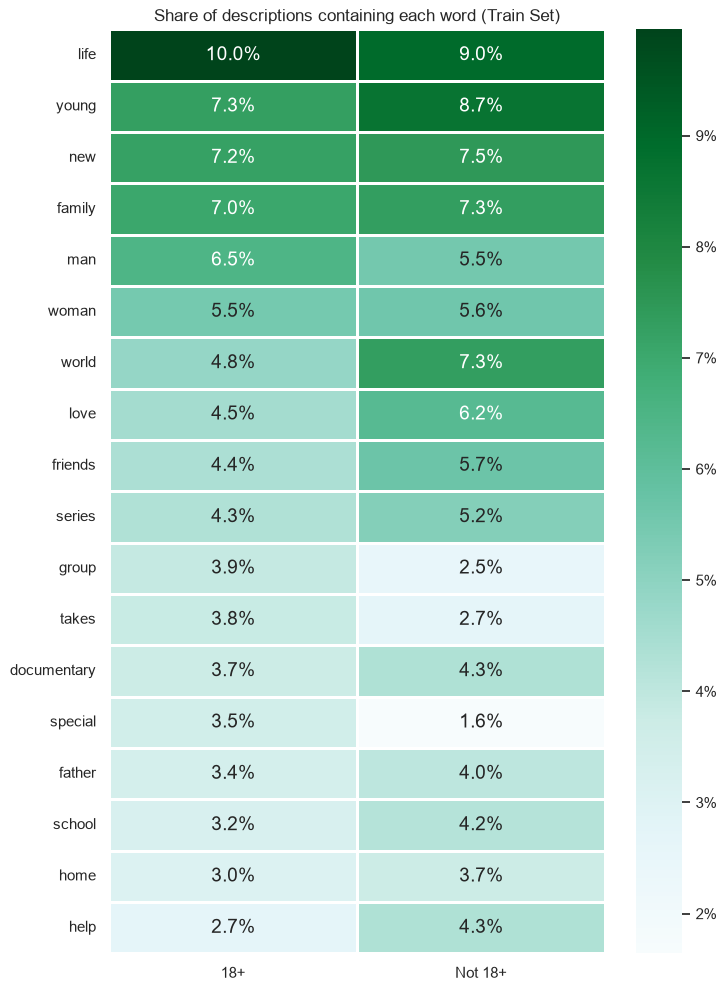

In [32]:
# Import CountVectorizer from sklearn.feature_extraction.text
from sklearn.feature_extraction.text import CountVectorizer

# Which words appear in each description (1 = present, 0 = absent) -- Train Set only
words = CountVectorizer(stop_words = "english", binary = True)
present = words.fit_transform(netflix_train["description"])
present = pd.DataFrame(present.toarray(), columns = words.get_feature_names_out(), index = netflix_train.index)

# Share of descriptions in each Class that contain each word
word_share = present.groupby(netflix_train["adult"]).mean().T

# Top 15 words of each Class, combined into one list
top_words = word_share["18+"].nlargest(15).index.union(word_share["Not 18+"].nlargest(15).index)
heat = word_share.loc[top_words].sort_values("18+", ascending = False)

# Heatmap of the most common words against Adult
f = plt.figure(figsize=(8, 12))
sb.heatmap(heat, annot = True, fmt = ".1%", cmap = "BuGn", linewidths = 1,
           annot_kws = {"size": 14}, cbar_kws = {"format": "{x:.0%}"})
plt.xlabel("")
plt.ylabel("")
plt.title("Share of descriptions containing each word (Train Set)")

#### Genres against Adult

Share of 18+ titles within each genre (genres with at least 80 titles in the Train Set).

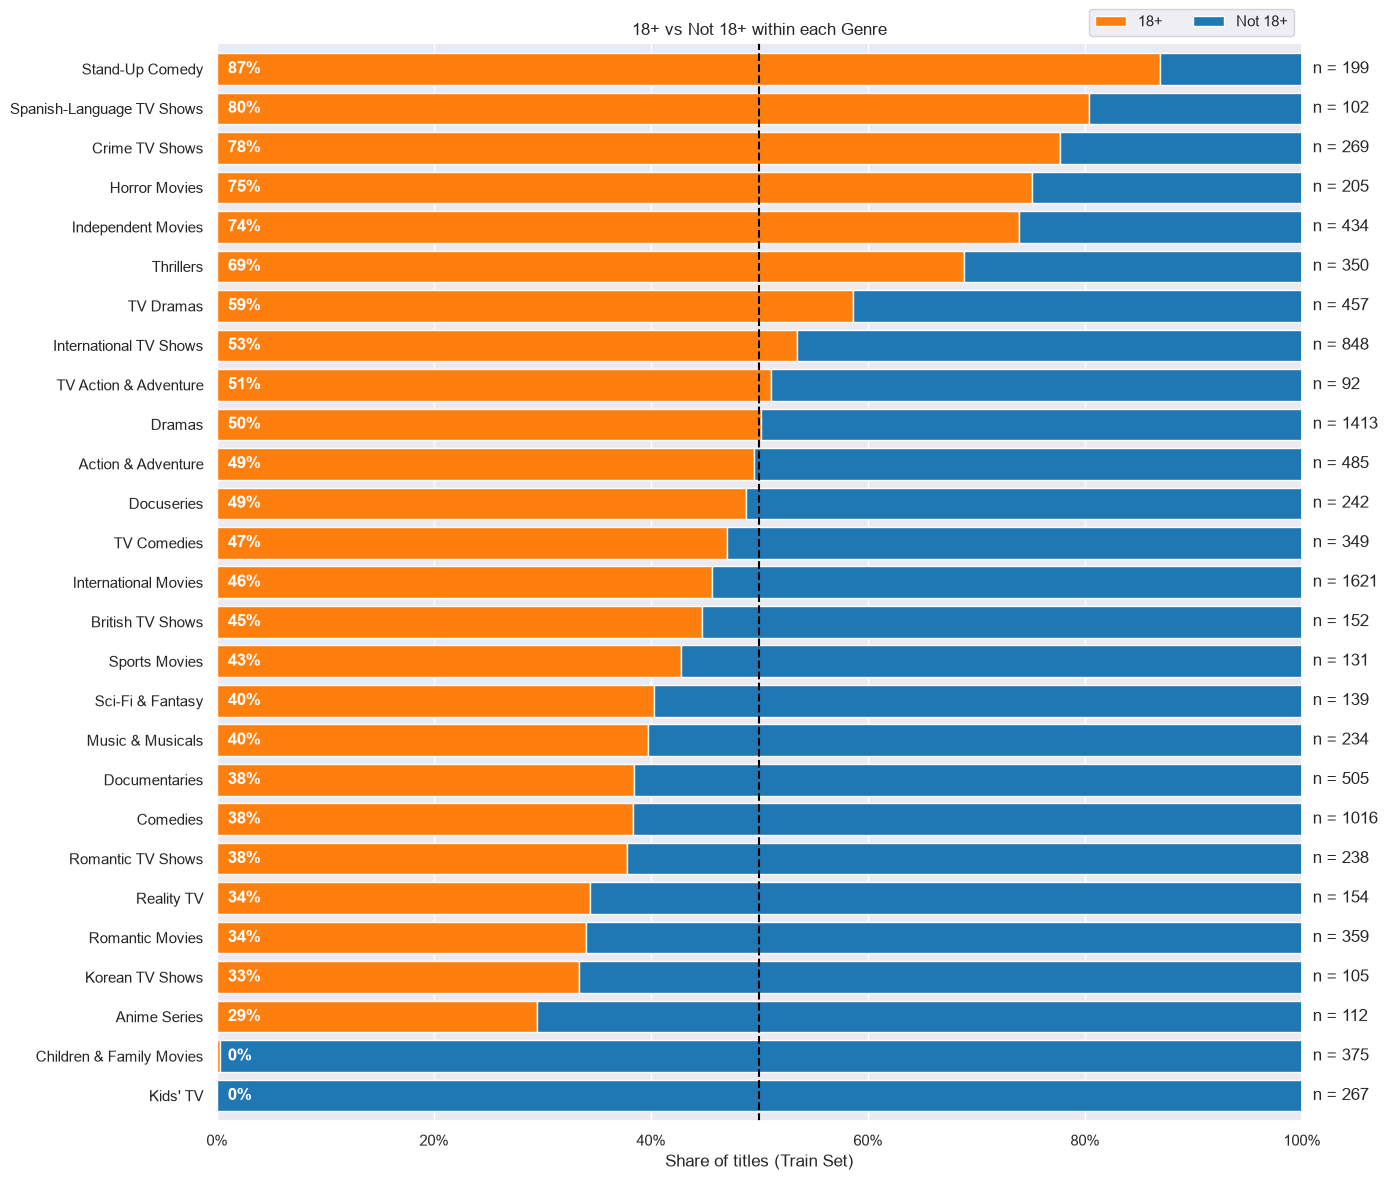

In [37]:
from matplotlib.ticker import PercentFormatter

# One row for each Genre of each title (Train Set)
genreDF = netflix_train[["listed_in", "adult"]].copy()
genreDF["listed_in"] = genreDF["listed_in"].str.split(", ")
genreDF = genreDF.explode("listed_in").reset_index(drop = True)

# Count the titles in each Genre and Class (genres with at least 80 titles)
genre_counts = genreDF.groupby(["listed_in", "adult"]).size().unstack(fill_value = 0)
genre_counts = genre_counts[genre_counts.sum(axis = 1) >= 80]

# Share of each Class within each Genre, sorted by share of 18+
genre_pct = genre_counts.div(genre_counts.sum(axis = 1), axis = 0)
genre_pct = genre_pct.sort_values("18+")
genre_share = genre_pct["18+"]

# 100% stacked bar : each bar is one Genre, split into 18+ and Not 18+
ax = genre_pct[["18+", "Not 18+"]].plot(kind = "barh", stacked = True, figsize = (14, 14),
                                         color = ["tab:orange", "tab:blue"], width = 0.8)

# Label each bar with its share of 18+ and its number of titles
for i, genre in enumerate(genre_pct.index):
    ax.text(0.01, i, f"{genre_pct.loc[genre, '18+']:.0%}", va = "center", color = "white", fontweight = "bold")
    ax.text(1.01, i, f"n = {genre_counts.loc[genre].sum()}", va = "center")

plt.axvline(0.5, color = "black", linestyle = "--")
ax.xaxis.set_major_formatter(PercentFormatter(1))
plt.xlim(0, 1)
plt.xlabel("Share of titles (Train Set)")
plt.ylabel("")
plt.title("18+ vs Not 18+ within each Genre")
plt.legend(loc = "lower right", bbox_to_anchor = (1.0, 1.0), ncol = 2)

---

## Naive Bayes Classifier

#### Convert Text to Word Counts

A model can only work with numbers, so each title's text is converted into word counts using `CountVectorizer`.  

**Why this prevents leakage :** the vocabulary is learnt from the **Train Set only** (`fit_transform`).  
The Validation Set is only **transformed** with that vocabulary, so a word that appears only in Validation titles teaches the model nothing.

In [40]:
# Import CountVectorizer, the model and the scoring function from sklearn
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import f1_score

# Learn the vocabulary from the Train Set only
vectorizer = CountVectorizer(token_pattern = r"(?u)\b\w+\b")
X_train_counts = vectorizer.fit_transform(netflix_train["text"])   # fit on Train
X_val_counts = vectorizer.transform(netflix_val["text"])           # transform Validation only

# Check the sizes (titles, words in vocabulary)
print("Train Counts      :", X_train_counts.shape)
print("Validation Counts :", X_val_counts.shape)


Train Counts      : (5204, 14927)
Validation Counts : (1735, 14927)


#### Choose the Smoothing Parameter -- on the Validation Set

`alpha` adds a small count to every word so no word has a probability of zero.  
Train a model for each `alpha` on the Train Set, score it on the Validation Set, and keep the best.  

**Why this prevents leakage :** `alpha` is chosen with the **Validation Set**, never the Test Set. Picking settings by Test scores would tune the model to the Test Set.

In [42]:
# Try different values of alpha : train on Train, score on Validation
alpha_scores = {}
for alpha in [0.1, 0.5, 1, 2, 3]:
    nbmodel = MultinomialNB(alpha = alpha)
    nbmodel.fit(X_train_counts, netflix_train["adult"])
    val_pred = nbmodel.predict(X_val_counts)
    alpha_scores[alpha] = f1_score(netflix_val["adult"], val_pred, average = "macro")
    print("alpha =", alpha, "\tValidation Macro-F1 :", round(alpha_scores[alpha], 3))

# Keep the best alpha
best_alpha = max(alpha_scores, key = alpha_scores.get)
print()
print("Best alpha :", best_alpha)

alpha = 0.1 	Validation Macro-F1 : 0.69
alpha = 0.5 	Validation Macro-F1 : 0.713
alpha = 1 	Validation Macro-F1 : 0.716
alpha = 2 	Validation Macro-F1 : 0.701
alpha = 3 	Validation Macro-F1 : 0.701

Best alpha : 1


#### Does Genre Help? -- decided on the Validation Set

Compare three Predictors -- **description only**, **genre only**, and **description + genre** -- trained on the Train Set and scored on the Validation Set.  
Each Predictor gets its own vocabulary, again learnt from the Train Set only.

In [43]:
for var in ["description", "genre", "text"]:
    vec = CountVectorizer(token_pattern = r"(?u)\b\w+\b")
    train_counts = vec.fit_transform(netflix_train[var])   
    val_counts = vec.transform(netflix_val[var])           

    model = MultinomialNB(alpha = best_alpha)
    model.fit(train_counts, netflix_train["adult"])
    val_pred = model.predict(val_counts)

    print("Predictor :", var)
    print("Validation Accuracy \t:", round(model.score(val_counts, netflix_val["adult"]), 3))
    print("Validation Macro-F1 \t:", round(f1_score(netflix_val["adult"], val_pred, average = "macro"), 3))
    print()

Predictor : description
Validation Accuracy 	: 0.685
Validation Macro-F1 	: 0.682

Predictor : genre
Validation Accuracy 	: 0.685
Validation Macro-F1 	: 0.677

Predictor : text
Validation Accuracy 	: 0.718
Validation Macro-F1 	: 0.716



#### Train the Final Model

All choices are now made (`alpha`, and description + genre as the Predictor), so the Validation Set has done its job.  
We retrain on **Train + Validation (80%)** so the final model learns from as much data as possible -- the Test Set is still untouched.  

The word counter is re-fitted on Train + Validation, and the Test Set is only **transformed** with that vocabulary.

In [44]:
netflix_final = pd.concat([netflix_train, netflix_val])

X_final, y_final = netflix_final["text"], netflix_final["adult"]
X_test, y_test = netflix_test["text"], netflix_test["adult"]

vectorizer = CountVectorizer(token_pattern = r"(?u)\b\w+\b")
X_final_counts = vectorizer.fit_transform(X_final)   
X_test_counts = vectorizer.transform(X_test)         

print("Final Train Counts :", X_final_counts.shape)
print("Test Counts        :", X_test_counts.shape)

Final Train Counts : (6939, 17151)
Test Counts        : (1735, 17151)


In [45]:
nbmodel = MultinomialNB(alpha = best_alpha)
nbmodel.fit(X_final_counts, y_final)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3201.,3738.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.77,-0.62]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U7](2,)","['18+','Not 18+']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 17151)","[[ 2.,12., 0.,..., 1., 1., 1.], [ 0.,18., 3.,..., 1., 0., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 17151)","[[-10.44, -8.98,-11.54,...,-10.85,-10.85,-10.85], [-11.67, -8.73,-10.28,...,-10.98,-11.67,-11.67]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,17151


#### Goodness of Fit of the Model

Check how good the predictions are on the data the final model was trained on (Train + Validation).    
Metrics : Classification Accuracy and Confusion Matrix.

Classification Accuracy 	: 0.909785271652976


Text(66.91216362847221, 0.5, 'Actual')

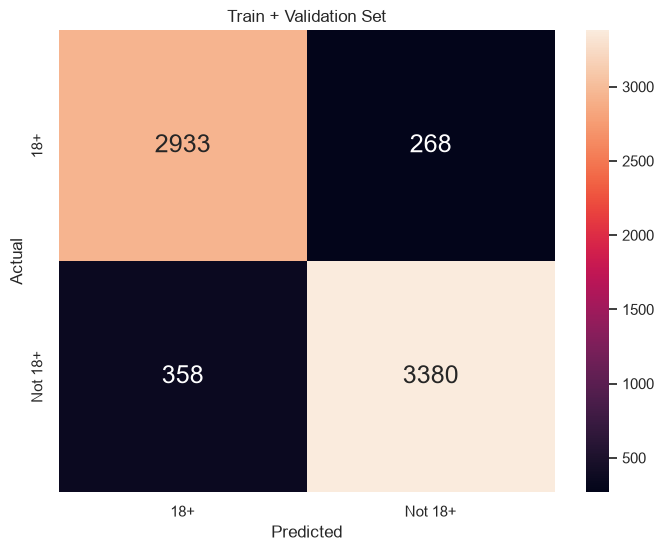

In [46]:
# Import confusion_matrix from sklearn
from sklearn.metrics import confusion_matrix

# Predict Adult corresponding to Text (Train + Validation)
y_final_pred = nbmodel.predict(X_final_counts)

# Print the Classification Accuracy
print("Classification Accuracy \t:", nbmodel.score(X_final_counts, y_final))

# Plot the two-way Confusion Matrix
f = plt.figure(figsize=(8, 6))
sb.heatmap(confusion_matrix(y_final, y_final_pred, labels = ["18+", "Not 18+"]),
           annot = True, fmt=".0f", annot_kws={"size": 18},
           xticklabels = ["18+", "Not 18+"], yticklabels = ["18+", "Not 18+"])
plt.title("Train + Validation Set")
plt.xlabel("Predicted")
plt.ylabel("Actual")

Check how good the predictions are on the Test Set -- the **first and only time** the Test Set is used.    
Metrics : Classification Accuracy and Confusion Matrix.

Classification Accuracy 	: 0.7170028818443804


Text(66.91216362847221, 0.5, 'Actual')

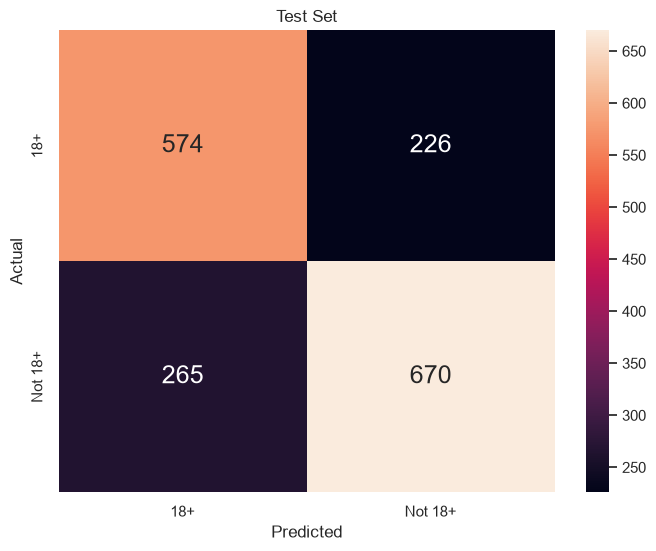

In [47]:
# Predict Adult corresponding to Text Test
y_test_pred = nbmodel.predict(X_test_counts)

# Print the Classification Accuracy
print("Classification Accuracy \t:", nbmodel.score(X_test_counts, y_test))

# Plot the two-way Confusion Matrix
f = plt.figure(figsize=(8, 6))
sb.heatmap(confusion_matrix(y_test, y_test_pred, labels = ["18+", "Not 18+"]),
           annot = True, fmt=".0f", annot_kws={"size": 18},
           xticklabels = ["18+", "Not 18+"], yticklabels = ["18+", "Not 18+"])
plt.title("Test Set")
plt.xlabel("Predicted")
plt.ylabel("Actual")

Look at Precision, Recall and F1-score for each class on the Test Set.

In [48]:
# Import classification_report from sklearn
from sklearn.metrics import classification_report

print(classification_report(y_test, y_test_pred))

              precision    recall  f1-score   support

         18+       0.68      0.72      0.70       800
     Not 18+       0.75      0.72      0.73       935

    accuracy                           0.72      1735
   macro avg       0.72      0.72      0.72      1735
weighted avg       0.72      0.72      0.72      1735



---

## What the Model Learnt

Compare the probability of each word in the two classes (learnt from Train + Validation).  
Words with a much higher probability in one class push the prediction towards that class.

In [50]:
# Words in the vocabulary
words = vectorizer.get_feature_names_out()

# Difference in log-probability : positive means more typical of 18+
adult_idx = list(nbmodel.classes_).index("18+")
other_idx = 1 - adult_idx
diff = pd.Series(nbmodel.feature_log_prob_[adult_idx] - nbmodel.feature_log_prob_[other_idx], index = words)

# Split into Genre tokens and Description words
genre_diff = diff[diff.index.str.startswith("g_")]
word_diff = diff[~diff.index.str.startswith("g_")]

print("Genres pointing to 18+ \t\t:", list(genre_diff.nlargest(10).index))
print("Genres pointing to Not 18+ \t:", list(genre_diff.nsmallest(10).index))
print()
print("Words pointing to 18+ \t\t:", list(word_diff.nlargest(10).index))
print("Words pointing to Not 18+ \t:", list(word_diff.nsmallest(10).index))

Genres pointing to 18+ 		: ['g_stand_up_comedy', 'g_tv_horror', 'g_crime_tv_shows', 'g_spanish_language_tv_shows', 'g_horror_movies', 'g_independent_movies', 'g_tv_mysteries', 'g_lgbtq_movies', 'g_thrillers', 'g_stand_up_comedy_and_talk_shows']
Genres pointing to Not 18+ 	: ['g_kids_tv', 'g_children_and_family_movies', 'g_faith_and_spirituality', 'g_science_and_nature_tv', 'g_anime_features', 'g_tv_sci_fi_and_fantasy', 'g_movies', 'g_teen_tv_shows', 'g_reality_tv', 'g_romantic_movies']

Words pointing to 18+ 		: ['horror', 'outrageous', 'rapper', 'sexuality', 'dystopian', 'injustice', 'link', 'outlaw', 'standup', 'trailer']
Words pointing to Not 18+ 	: ['bheem', 'fairy', 'ocean', 'sidekick', 'barbie', 'rainbow', 'animated', 'amazing', 'flying', 'interactive']


---

## Error Analysis

Which of the original ratings are misclassified most often on the Test Set?  
This only **describes** the final result -- we do not go back and change the model because of it, so it does not leak.

In [51]:
# Summarize the Actuals and Predictions
y_test_pred = pd.DataFrame(y_test_pred, columns = ["PredAdult"], index = y_test.index)
netflix_acc = pd.concat([netflix_test[["title", "rating", "listed_in", "description", "adult"]],
                         y_test_pred], axis = 1)
netflix_acc["Correct"] = netflix_acc["adult"] == netflix_acc["PredAdult"]

# Accuracy for each original Rating
print(netflix_acc.groupby("rating")["Correct"].mean().sort_values().round(2))

rating
NC-17       0.50
TV-14       0.56
PG-13       0.57
TV-MA       0.70
R           0.80
TV-PG       0.82
G           0.83
TV-G        0.91
PG          0.92
TV-Y        1.00
TV-Y7       1.00
TV-Y7-FV    1.00
Name: Correct, dtype: float64


In [52]:
# A few Misclassified Titles
netflix_acc[netflix_acc["Correct"] == False].head(10)

,title,rating,listed_in,description,adult,PredAdult,Correct
1211,Mucize,TV-14,"Dramas, International Movies",Sent away from his family to a remote mountain...,Not 18+,18+,False
3840,The Society,TV-MA,"TV Dramas, Teen TV Shows",When everyone else mysteriously vanishes from ...,18+,Not 18+,False
4709,The Originals,TV-14,"TV Dramas, TV Horror, TV Mysteries",The Mikaelsons move to New Orleans and form an...,Not 18+,18+,False
6971,Hinterland,TV-14,"British TV Shows, Crime TV Shows, Internationa...",Forsaking London for the rustic landscapes of ...,Not 18+,18+,False
2103,Class of '83,TV-14,"Dramas, International Movies, Thrillers","Demoted to an academy job, a cop trains five f...",Not 18+,18+,False
4751,Extinction,TV-MA,"Action & Adventure, Dramas, Sci-Fi & Fantasy","Plagued by dreams of an alien invasion, a fami...",18+,Not 18+,False
4632,The Good Cop,TV-14,"Crime TV Shows, TV Comedies, TV Dramas","When he's not solving murders, a pathologicall...",Not 18+,18+,False
3132,Dil Dhadakne Do,TV-MA,"Comedies, Dramas, International Movies",While hosting a shipboard holiday for relative...,18+,Not 18+,False
2545,Andaz Apna Apna,TV-14,"Action & Adventure, Comedies, Cult Movies",Broke and with no concrete plans for the futur...,Not 18+,18+,False
5763,Be with You,TV-14,"International TV Shows, Romantic TV Shows, TV ...",After reconnecting with their girlhood crushes...,Not 18+,18+,False


---

## Prediction for Specific Titles

Let's predict the class for a few specific titles, along with the Class Probabilities.  

**Why this prevents leakage :** the titles are picked from the **Test Set**. A title from the Train or Validation Set would show how well the model remembers, not how well it predicts.

In [53]:
# Extract Titles for Prediction (all four are in the Test Set)
netflix_pred = netflix_test[netflix_test["title"].isin(["Black Mirror", "Squid Game", "Never Have I Ever", "Octonauts: Above & Beyond"])]

# Predict Response corresponding to Predictors
X_pred = vectorizer.transform(netflix_pred["text"])
y_pred = nbmodel.predict(X_pred)

# Summarize the Actuals and Predictions
y_pred = pd.DataFrame(y_pred, columns = ["PredAdult"], index = netflix_pred.index)
netflix_pred_acc = pd.concat([netflix_pred[["title", "rating", "adult"]], y_pred], axis = 1)
netflix_pred_acc

,title,rating,adult,PredAdult
459,Never Have I Ever,TV-14,Not 18+,Not 18+
33,Squid Game,TV-MA,18+,Not 18+
3774,Black Mirror,TV-MA,18+,18+
98,Octonauts: Above & Beyond,TV-Y,Not 18+,Not 18+


In [54]:
# Predict Probabilities corresponding to Predictors
y_prob = nbmodel.predict_proba(X_pred)
np.set_printoptions(precision = 3)
print(nbmodel.classes_)
print(y_prob)

['18+' 'Not 18+']
[[4.651e-03 9.953e-01]
 [5.099e-02 9.490e-01]
 [9.497e-01 5.032e-02]
 [3.207e-08 1.000e+00]]
